# Random LD Seq., QMC, and Fast Kernel Methods

## Setup

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/QMCSoftware/QMCSoftware/blob/develop/demos/talk_paper_demos/Sorokin_random_LD_seq_QMC_fast_kernel_methods_2026/Sorokin_random_LD_seq_QMC_fast_kernel_methods_2026.ipynb)

In [1]:
# @title Execute this cell to install dependencies
try:
  import google.colab
  IN_COLAB = True
except ImportError:
  IN_COLAB = False
if IN_COLAB:
  !pip install -q qmcpy
  !pip install -q sympy torch tueplots
  !tmp=$(mktemp) && if { apt-get update -qq && DEBIAN_FRONTEND=noninteractive apt-get install -y -qq --no-install-recommends texlive-latex-base texlive-fonts-recommended texlive-latex-extra cm-super dvipng; } >"$tmp" 2>&1; then rm -f "$tmp"; else status=$?; cat "$tmp"; rm -f "$tmp"; exit $status; fi


In [2]:
import qmcpy as qp
import numpy as np
import timeit
from collections import OrderedDict
import os
import scipy.stats
import scipy.linalg
import time
import torch
import sympy
import gc
import itertools

In [3]:
import matplotlib 
from matplotlib import pyplot
from tueplots import cycler
from tueplots.bundles import probnum2025
from tueplots.constants import markers
from tueplots.constants.color import palettes
matplotlib.rcParams['figure.dpi'] = 256
_golden = (1 + 5 ** 0.5) / 2
MW1 = 240/72
MW2 = 500/72
MH1 = MW1/_golden
MH2 = MW2/_golden
COLORS = palettes.tue_plot
MARKERS = markers.o_sized
pyplot.rcParams.update(probnum2025())
pyplot.rcParams.update(cycler.cycler(color=COLORS,marker=MARKERS))
os.makedirs("outputs", exist_ok=True)

## Snippets

### Point Sets

In [4]:
%%time 
lattice = qp.Lattice(
    dimension = 52,
    randomize = "shift", # or None for unrandomized
    replications = 16, # R
    order = "natural", # or "linear"
    seed = None, # pass integer seed for reproducibility
    generating_vector = "mps.exod2_base2_m20_CKN.txt")
x = lattice(2**10) # (16, 1024, 52) shaped numpy.ndarray

CPU times: user 2.45 ms, sys: 2.26 ms, total: 4.71 ms
Wall time: 4.07 ms


In [5]:
%%time
dnb2 = qp.DigitalNetB2(
    dimension = 52, 
    randomize = "LMS DS", # Matousek's LMS + DS
    # or ["NUS","DS","LMS",None]
    t = 64, # number of LMS bits, i.e., rows in S_j
    alpha = 2, # interlacing factor for higher order nets
    replications = 16, # R
    order = "natural", # or "Gray"
    seed = None, # integer seed for reproducibility
    generating_matrices = "joe_kuo.6.21201.txt")
x = dnb2(2**10) # (16, 1024, 52) shaped numpy.ndarray

CPU times: user 37 ms, sys: 5.63 ms, total: 42.6 ms
Wall time: 47.5 ms


In [6]:
%%time
faure = qp.Faure(
    dimension = 52, 
    randomize = "LMS DP", # Matousek's LMS + DP
    # or ["LMS DS","LMS","DP","DS","NUS",None]
    replications = 16, # R
    seed = None) # pass integer seed for reproducibility
x = faure(53**2) # (16, 2809, 52) shaped numpy.ndarray

CPU times: user 117 ms, sys: 26.5 ms, total: 143 ms
Wall time: 139 ms


In [7]:
%%time 
halton = qp.Halton(
    dimension = 52, 
    randomize = "LMS DP", # Matousek's LMS + DP
    # or ["LMS DS","LMS","DP","DS","NUS","QRNG",None]
    t = 64, # number of LMS digits, i.e.,  rows in S_j
    replications = 16, # R
    seed = None) #  pass integer seed for reproducibility
x = halton(2**10) # (16, 1024, 52) shaped numpy.ndarray

CPU times: user 287 ms, sys: 62.1 ms, total: 349 ms
Wall time: 349 ms


### Kernel Methods

#### Lattice + FFTBR + IFFTBR

In [8]:
d = 3 # dimension 
m = 10 # will generate 2^m points
n = 2**m # number of points
lattice = qp.Lattice(d) # defaults to natural order
kernel = qp.KernelShiftInvar(
    d, # dimension 
    alpha = [1,2,3], # per-dim smoothness parameters
    weights = [1,1/2,1/4]) # per-dim product weights
x = lattice(n_min=0,n_max=n) # shape=(n, d) lattice
y = np.random.rand(n) # shape=(n,) random uniforms
# fast matrix multiplication and linear system solve
k1 = kernel(x,x[0]) # shape=(n,) first col of Gram matrix
lam = np.sqrt(n)*qp.fftbr(k1) # vector of eigenvalues
yt = qp.fftbr(y)
u = qp.ifftbr(yt*lam) # fast matrix multiplication 
v = qp.ifftbr(yt/lam) # fast linear system solve
# efficient fast transform updates
ynew = np.random.rand(n) # shape=(n,) new random uniforms
omega = qp.omega_fftbr(m) # shape=(n,)
ytnew = qp.fftbr(ynew) # shape=(n,)
ytfull = 1/np.sqrt(2)*np.hstack([ # ytfull shape=(2n,)
        yt+omega*ytnew, #  shape=(n,) first half
        yt-omega*ytnew]) # shape=(n,) second half

In [9]:
# slow matrix multiplication and linear system solve
kmat = kernel(x[:,None,:],x[None,:,:]) # shape=(n,n)
u_slow = kmat@y # matrix multiplication
v_slow = np.linalg.solve(kmat,y) # solve a linear system
# verify correctness
assert np.allclose(u,u_slow)
assert np.allclose(v,v_slow)
# get next samples 
xnew = lattice(n_min=n,n_max=2*n) # shape=(n,d) new lattice points
k1new = kernel(xnew,x[0]) # shape=(n,) new values in the first column
# inefficient fast transform update 
k1full = np.concatenate([k1,k1new]) # shape=(2*n,) full first column
lamfull_inefficient = np.sqrt(2*n)*qp.fftbr(k1full) # shape=(2*n,) full eigenvalues
yfull = np.concatenate([y,ynew]) # shape=(2*n,) full random values
ytfull_inefficient = qp.fftbr(yfull) # shape=(2*n,) full transformed points
# efficient fast transform updates
lamnew = np.sqrt(n)*qp.fftbr(k1new) # shape=(n,) new eigenvalues
lamfull = np.hstack([lam+omega*lamnew,lam-omega*lamnew])
# verify correctness
assert np.allclose(lamfull,lamfull_inefficient)
assert np.allclose(ytfull,ytfull_inefficient)

In [10]:
rel_mult_err = np.linalg.norm(u-kmat@y)/np.linalg.norm(kmat@y)
rel_solve_res = np.linalg.norm(kmat@v-y)/np.linalg.norm(y)
print("relative multiplication error: %.1e"%rel_mult_err)
print("normalized solve residual:     %.1e"%rel_solve_res)

relative multiplication error: 7.5e-16
normalized solve residual:     9.8e-14


#### Digital Net + FWHT

In [11]:
d = 3 # dimension 
m = 10 # will generate 2^m points
n = 2**m # number of points
dnb2 = qp.DigitalNetB2(d) # defaults to natural order
kernel = qp.KernelDigShiftInvar(
    d, # dimension 
    t = dnb2.t, # bits in int representation of points
    alpha = [1,2,3], # per-dim smoothness parameters
    weights = [1,1/2,1/4]) # per-dim product weights
x = dnb2(n_min=0,n_max=n) # shape=(n, d) digital net
y = np.random.rand(n) # shape=(n,) random uniforms
# fast matrix multiplication and linear system solve
k1 = kernel(x,x[0]) # shape=(n,) first col of Gram matrix
lam = np.sqrt(n)*qp.fwht(k1) # vector of eigenvalues
yt = qp.fwht(y)
u = qp.fwht(yt*lam) # fast matrix multiplication 
v = qp.fwht(yt/lam) # fast linear system solve
# efficient fast transform updates
ynew = np.random.rand(n) # shape=(n,) new random uniforms
omega = qp.omega_fwht(m) # shape=(n,)
ytnew = qp.fwht(ynew) # shape=(n,)
ytfull = 1/np.sqrt(2)*np.hstack([ # ytfull shape=(2n,)
        yt+omega*ytnew, #  shape=(n,) first half
        yt-omega*ytnew]) # shape=(n,) second half

In [12]:
# slow matrix multiplication and linear system solve
kmat = kernel(x[:,None,:],x[None,:,:]) # shape=(n,n)
u_slow = kmat@y # matrix multiplication
v_slow = np.linalg.solve(kmat,y) # solve a linear system
# verify correctness
assert np.allclose(u,u_slow)
assert np.allclose(v,v_slow)
# get next samples 
xnew = dnb2(n_min=n,n_max=2*n) # shape=(n,d) new digital net points
k1new = kernel(xnew,x[0]) # shape=(n,) new values in the first column
# inefficient fast transform update 
k1full = np.concatenate([k1,k1new]) # shape=(2*n,) full first column
lamfull_inefficient = np.sqrt(2*n)*qp.fwht(k1full) # shape=(2*n,) full eigenvalues
yfull = np.concatenate([y,ynew]) # shape=(2*n,) full random values
ytfull_inefficient = qp.fwht(yfull) # shape=(2*n,) full transformed points
# efficient fast transform updates
lamnew = np.sqrt(n)*qp.fwht(k1new) # shape=(n,) new eigenvalues
lamfull = np.hstack([lam+omega*lamnew,lam-omega*lamnew])
# verify correctness
assert np.allclose(lamfull,lamfull_inefficient)
assert np.allclose(ytfull,ytfull_inefficient)

In [13]:
rel_mult_err = np.linalg.norm(u-kmat@y)/np.linalg.norm(kmat@y)
rel_solve_res = np.linalg.norm(kmat@v-y)/np.linalg.norm(y)
print("relative multiplication error: %.1e"%rel_mult_err)
print("normalized solve residual:     %.1e"%rel_solve_res)

relative multiplication error: 2.1e-15
normalized solve residual:     7.9e-14


#### Timing for Gram matrix ops

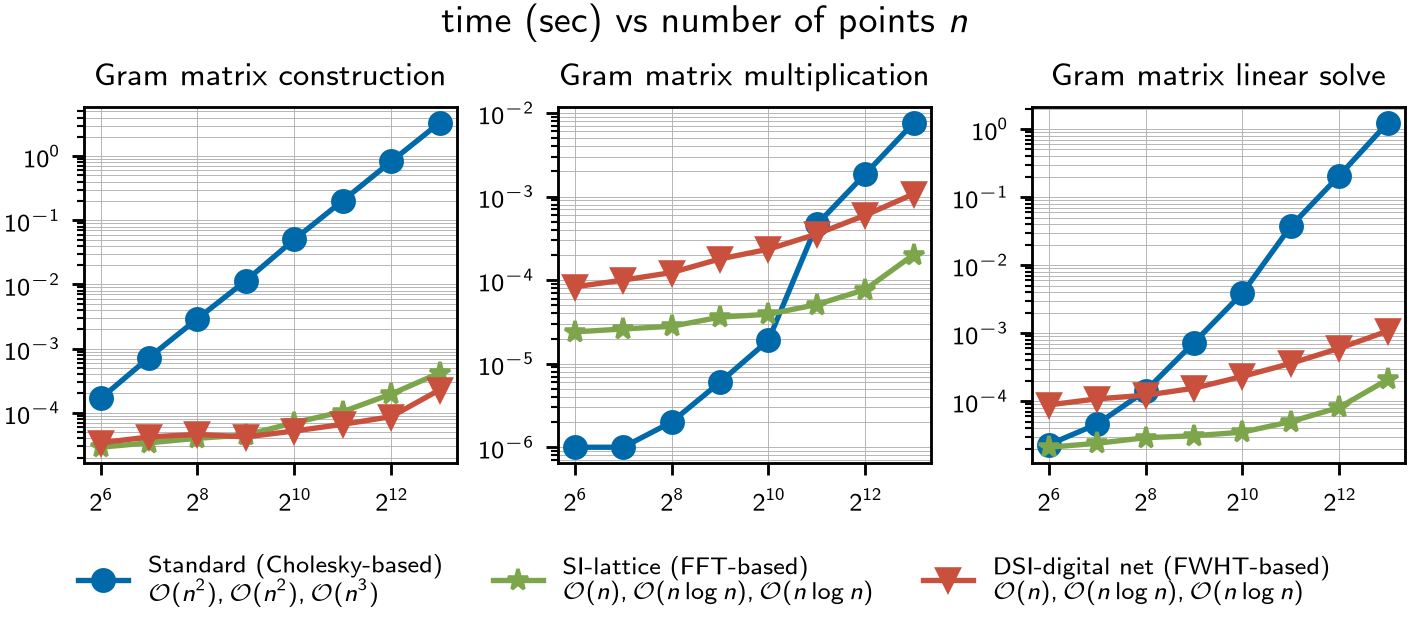

In [ ]:
trials = 5
ms = np.arange(5,14)
times_std_gram = np.zeros((trials,len(ms)))
times_std_mult = np.zeros((trials,len(ms)))
times_std_div = np.zeros((trials,len(ms)))
times_lat_gram = np.zeros((trials,len(ms)))
times_lat_mult = np.zeros((trials,len(ms)))
times_lat_div = np.zeros((trials,len(ms)))
times_net_gram = np.zeros((trials,len(ms)))
times_net_mult = np.zeros((trials,len(ms)))
times_net_div = np.zeros((trials,len(ms)))
kernel_lat = qp.KernelShiftInvar(d=1)
kernel_net = qp.KernelDigShiftInvar(d=1,t=int(ms.max()))
for i,m in enumerate(ms):
    n = 2**m
    x = np.arange(n)[:,None]/n # linear-order points; FFTBR expects natural order, so outputs are for timing only (accuracy is checked in the cells above)
    y = np.random.rand(n)
    # std 
    #   std gram
    for t in range(trials):
        t0 = time.process_time()
        kmat = kernel_lat(x[:,None,:],x[None,:,:])
        times_std_gram[t,i] = time.process_time()-t0
    #   std mult
    for t in range(trials):
        t0 = time.process_time()
        u_std = kmat@y
        times_std_mult[t,i] = time.process_time()-t0
    #   std div 
    for t in range(trials):
        t0 = time.process_time()
        c,L = scipy.linalg.cho_factor(kmat)
        v_std = scipy.linalg.cho_solve((c,L),y)
        times_std_div[t,i] = time.process_time()-t0
    # lat
    #   lat gram
    for t in range(trials):
        t0 = time.process_time()
        k1_lat = kernel_lat(x,x[0])
        times_lat_gram[t,i] = time.process_time()-t0
    #   lat mult
    for t in range(trials):
        t0 = time.process_time()
        lam_lat = np.sqrt(n)*qp.fftbr(k1_lat)
        yt_lat = qp.fftbr(y)
        u_lat = qp.ifftbr(yt_lat*lam_lat)
        times_lat_mult[t,i] = time.process_time()-t0
    #   lat div
    for t in range(trials):
        t0 = time.process_time()
        lam_lat = np.sqrt(n)*qp.fftbr(k1_lat)
        yt_lat = qp.fftbr(y)
        v_lat = qp.ifftbr(yt_lat/lam_lat)
        times_lat_div[t,i] = time.process_time()-t0
    # net
    #   net gram
    for t in range(trials):
        t0 = time.process_time()
        k1_net = kernel_net(x,x[0])
        times_net_gram[t,i] = time.process_time()-t0
    #   net mult
    for t in range(trials):
        t0 = time.process_time()
        lam_net = np.sqrt(n)*qp.fwht(k1_net)
        yt_net = qp.fwht(y)
        u_net = qp.fwht(yt_net*lam_net)
        times_net_mult[t,i] = time.process_time()-t0
    #   net div
    for t in range(trials):
        t0 = time.process_time()
        lam_net = np.sqrt(n)*qp.fwht(k1_net)
        yt_net = qp.fwht(y)
        v_net = qp.fwht(yt_net/lam_net)
        times_net_div[t,i] = time.process_time()-t0
fig,ax = pyplot.subplots(nrows=1,ncols=3,figsize=(4/5*MW2,9/10*MW2/3),sharey=False,sharex=True)
ax[0].plot(2**ms[1:],np.min(times_std_gram[:,1:],axis=0),color=COLORS[3],label='Standard (Cholesky-based)\n'+r"$\mathcal{O}(n^2), \mathcal{O}(n^2), \mathcal{O}(n^3)$")
ax[0].plot(2**ms[1:],np.min(times_lat_gram[:,1:],axis=0),color=COLORS[5],label='SI-lattice (FFT-based)\n'+r"$\mathcal{O}(n), \mathcal{O}(n \log n), \mathcal{O}(n \log n)$")
ax[0].plot(2**ms[1:],np.min(times_net_gram[:,1:],axis=0),color=COLORS[6],label='DSI-digital net (FWHT-based)\n'+r"$\mathcal{O}(n), \mathcal{O}(n \log n), \mathcal{O}(n \log n)$")
ax[1].plot(2**ms[1:],np.min(times_std_mult[:,1:],axis=0),color=COLORS[3])
ax[1].plot(2**ms[1:],np.min(times_lat_mult[:,1:],axis=0),color=COLORS[5])
ax[1].plot(2**ms[1:],np.min(times_net_mult[:,1:],axis=0),color=COLORS[6])
ax[2].plot(2**ms[1:],np.min(times_std_div[:,1:],axis=0),color=COLORS[3])
ax[2].plot(2**ms[1:],np.min(times_lat_div[:,1:],axis=0),color=COLORS[5])
ax[2].plot(2**ms[1:],np.min(times_net_div[:,1:],axis=0),color=COLORS[6])
for j in range(3):
    ax[j].set_yscale("log",base=10)
    ax[j].set_xscale("log",base=2)
    ax[j].grid(True,which='both',linewidth=0.25)
fig.suptitle(r"time (sec) vs number of points $n$")
ax[0].set_title("Gram matrix construction")
ax[1].set_title("Gram matrix multiplication")
ax[2].set_title("Gram matrix linear solve")
fig.legend(loc='upper center',frameon=False,bbox_to_anchor=(0.5,-0.01
),ncols=3)
fig.savefig("outputs/time_kernel_ops.png",format="png",dpi=1024,transparent=True,bbox_inches="tight")

### Integration

In [13]:
import scipy.stats
def gen_corner_peak_2(x):
    # x.shape=(...,n,d), e.g., (n,d) or (R,n,d) 
    d = x.shape[-1]
    c_tilde = 1/np.arange(1,d+1)**2
    c = 0.25*c_tilde/np.sum(c_tilde)
    y = (1+np.sum(c*x,axis=-1))**(-(d+1)) 
    return y # y.shape=(...,n), e.g., (n,) or (R,n)
R = 10 # number of randomizations
n = 2**15 # number of points 
d = 50 # dimension
dnb2 = qp.DigitalNet(d, replications=R, seed=7, alpha=3)
x = dnb2(n) # x.shape=(R,n,d)
y = gen_corner_peak_2(x) # y.shape=(R,n) 
muhats_r = np.mean(y,axis=1) # muhats_r.shape=(R,)
muhat = np.mean(muhats_r) # muhat is a scalar 
print(muhat)
""" 0.014936813948394042 """
alpha = 0.01 # uncertainty level
t_star = -scipy.stats.t.ppf(alpha/2,df=R-1) # quantile
sigmahat = np.std(muhats_r,ddof=1) # unbiased estimate
std_error = t_star*sigmahat/np.sqrt(R)
print(std_error)
""" 5.247445301861484e-07 """
conf_int = [muhat-std_error,muhat+std_error]

0.014936813948394042
5.24744530186179e-07


In [14]:
def gen_corner_peak_2(x):
    # x.shape=(...,n,d), e.g., (n,d) or (R,n,d) 
    d = x.shape[-1] 
    c_tilde = 1/np.arange(1,d+1)**2
    c = 0.25*c_tilde/np.sum(c_tilde)
    y = (1+np.sum(c*x,axis=-1))**(-(d+1)) 
    return y # y.shape=(...,n), e.g., (n,) or (R,n)
R = 10
d = 50 
dnb2 = qp.DigitalNet(d, replications=R, seed=7, alpha=3)
true_measure = qp.Uniform(
    sampler = dnb2,
    lower_bound = 0,
    upper_bound = 1)
integrand = qp.CustomFun(
    true_measure = true_measure,
    g = gen_corner_peak_2)
# equivalent to 
# integrand = qp.Genz(
#   sampler = dnb2,
#   kind_func = "CORNER PEAK",
#   kind_coeff = 2)
qmc_algo = qp.CubQMCRepStudentT(integrand, abs_tol=1e-4)
solution,data = qmc_algo.integrate() # run adaptive QMC 
print(solution)
""" 0.014950908095474802 """
conf_int = [data.comb_bound_low,data.comb_bound_high]
std_error = (conf_int[1]-conf_int[0])/2
print(std_error)
""" 2.7968149935497788e-05 """
print(data)
"""
Data (Data)
    solution        0.015
    comb_bound_low  0.015
    comb_bound_high 0.015
    comb_bound_diff 5.59e-05
    n               10240
    n_rep           2^(10)
    time_integrate  0.019
CubQMCRepStudentT (AbstractStoppingCriterion)
    alpha           0.010
    abs_tol         1.00e-04
    rel_tol         0
    n_init          2^(8)
DigitalNetB2 (AbstractLDDiscreteDistribution)
    d               50
    replications    10
    randomize       LMS DS
    gen_mats_source joe_kuo.6.21201.txt
    order           RADICAL INVERSE
    t               63
    alpha           3
    entropy         7
"""

0.014950908095474802
2.7968149935497788e-05
Data (Data)
    solution        0.015
    comb_bound_low  0.015
    comb_bound_high 0.015
    comb_bound_diff 5.59e-05
    comb_flags      1
    n_total         10240
    n               10240
    n_rep           2^(10)
    time_integrate  0.002
CubQMCRepStudentT (AbstractStoppingCriterion)
    inflate         1
    alpha           0.010
    abs_tol         1.00e-04
    rel_tol         0
    n_init          2^(8)
    n_limit         2^(30)
CustomFun (AbstractIntegrand)
Uniform (AbstractTrueMeasure)
    lower_bound     0
    upper_bound     1
    mean            [0.5 0.5 0.5 ... 0.5 0.5 0.5]
    variance        [0.083 0.083 0.083 ... 0.083 0.083 0.083]
    standard_deviation [0.289 0.289 0.289 ... 0.289 0.289 0.289]
    covariance      <DIAgonal sparse matrix of dtype 'float64'
                    	with 50 stored elements (1 diagonals) and shape (50, 50)>
                      Coords	Values
                      (0, 0)	0.08333333333333333
    

'\nData (Data)\n    solution        0.015\n    comb_bound_low  0.015\n    comb_bound_high 0.015\n    comb_bound_diff 5.59e-05\n    n               10240\n    n_rep           2^(10)\n    time_integrate  0.019\nCubQMCRepStudentT (AbstractStoppingCriterion)\n    alpha           0.010\n    abs_tol         1.00e-04\n    rel_tol         0\n    n_init          2^(8)\nDigitalNetB2 (AbstractLDDiscreteDistribution)\n    d               50\n    replications    10\n    randomize       LMS DS\n    gen_mats_source joe_kuo.6.21201.txt\n    order           RADICAL INVERSE\n    t               63\n    alpha           3\n    entropy         7\n'

## Pointsets

In [15]:
m = 10 # n = 2^m
n = 2**m # number of points
d = 2 # dimensions

In [16]:
pointsets = OrderedDict({
    "IID": (qp.IIDStdUniform(d,seed=11).gen_samples(n),{"color":COLORS[2]}),
    "Lattice Shift": (qp.Lattice(d,seed=11).gen_samples(n),{"color":COLORS[5]}),
    "Halton LMS DP": (qp.Halton(d,randomize="LMS_PERM",seed=11).gen_samples(n),{"color":COLORS[1]}),
    "Halton NUS": (qp.Halton(d,randomize="NUS",seed=11).gen_samples(n),{"color":COLORS[4]}),
    r"DN${}_{1}$ LMS DS": (qp.DigitalNetB2(d,randomize="LMS_DS",seed=11).gen_samples(n),{"color":COLORS[0]}),
    r"DN${}_{2}$ LMS DS": (qp.DigitalNetB2(d,randomize="LMS_DS",alpha=2,seed=11).gen_samples(n),{"color":COLORS[0]}),
    r"DN${}_{3}$ LMS DS": (qp.DigitalNetB2(d,randomize="LMS_DS",alpha=3,seed=11).gen_samples(n),{"color":COLORS[0]}),
    r"DN${}_{4}$ LMS DS": (qp.DigitalNetB2(d,randomize="LMS_DS",alpha=4,seed=11).gen_samples(n),{"color":COLORS[0]}),
    r"DN${}_{1}$ NUS": (qp.DigitalNetB2(d,randomize="NUS",seed=11).gen_samples(n),{"color":COLORS[3]}),
    r"DN${}_{2}$ NUS": (qp.DigitalNetB2(d,randomize="NUS",alpha=2,seed=11).gen_samples(n),{"color":COLORS[3]}),
    r"DN${}_{3}$ NUS": (qp.DigitalNetB2(d,randomize="NUS",alpha=3,seed=11).gen_samples(n),{"color":COLORS[3]}),
    r"DN${}_{4}$ NUS": (qp.DigitalNetB2(d,randomize="NUS",alpha=4,seed=11).gen_samples(n),{"color":COLORS[3]}),
})

/var/folders/vp/7qrx483x7t595m2wjkkc_kvr0000gn/T/ipykernel_46872/604512548.py:3: UserWarning: The Figure parameters 'tight_layout' and 'constrained_layout' cannot be used together. Please use 'layout' parameter
  fig,ax = pyplot.subplots(nrows=nrows,ncols=ncols,figsize=(MW2,MW2/ncols*nrows),constrained_layout=False,tight_layout=False)#figsize=(ncols*3,nrows*3))


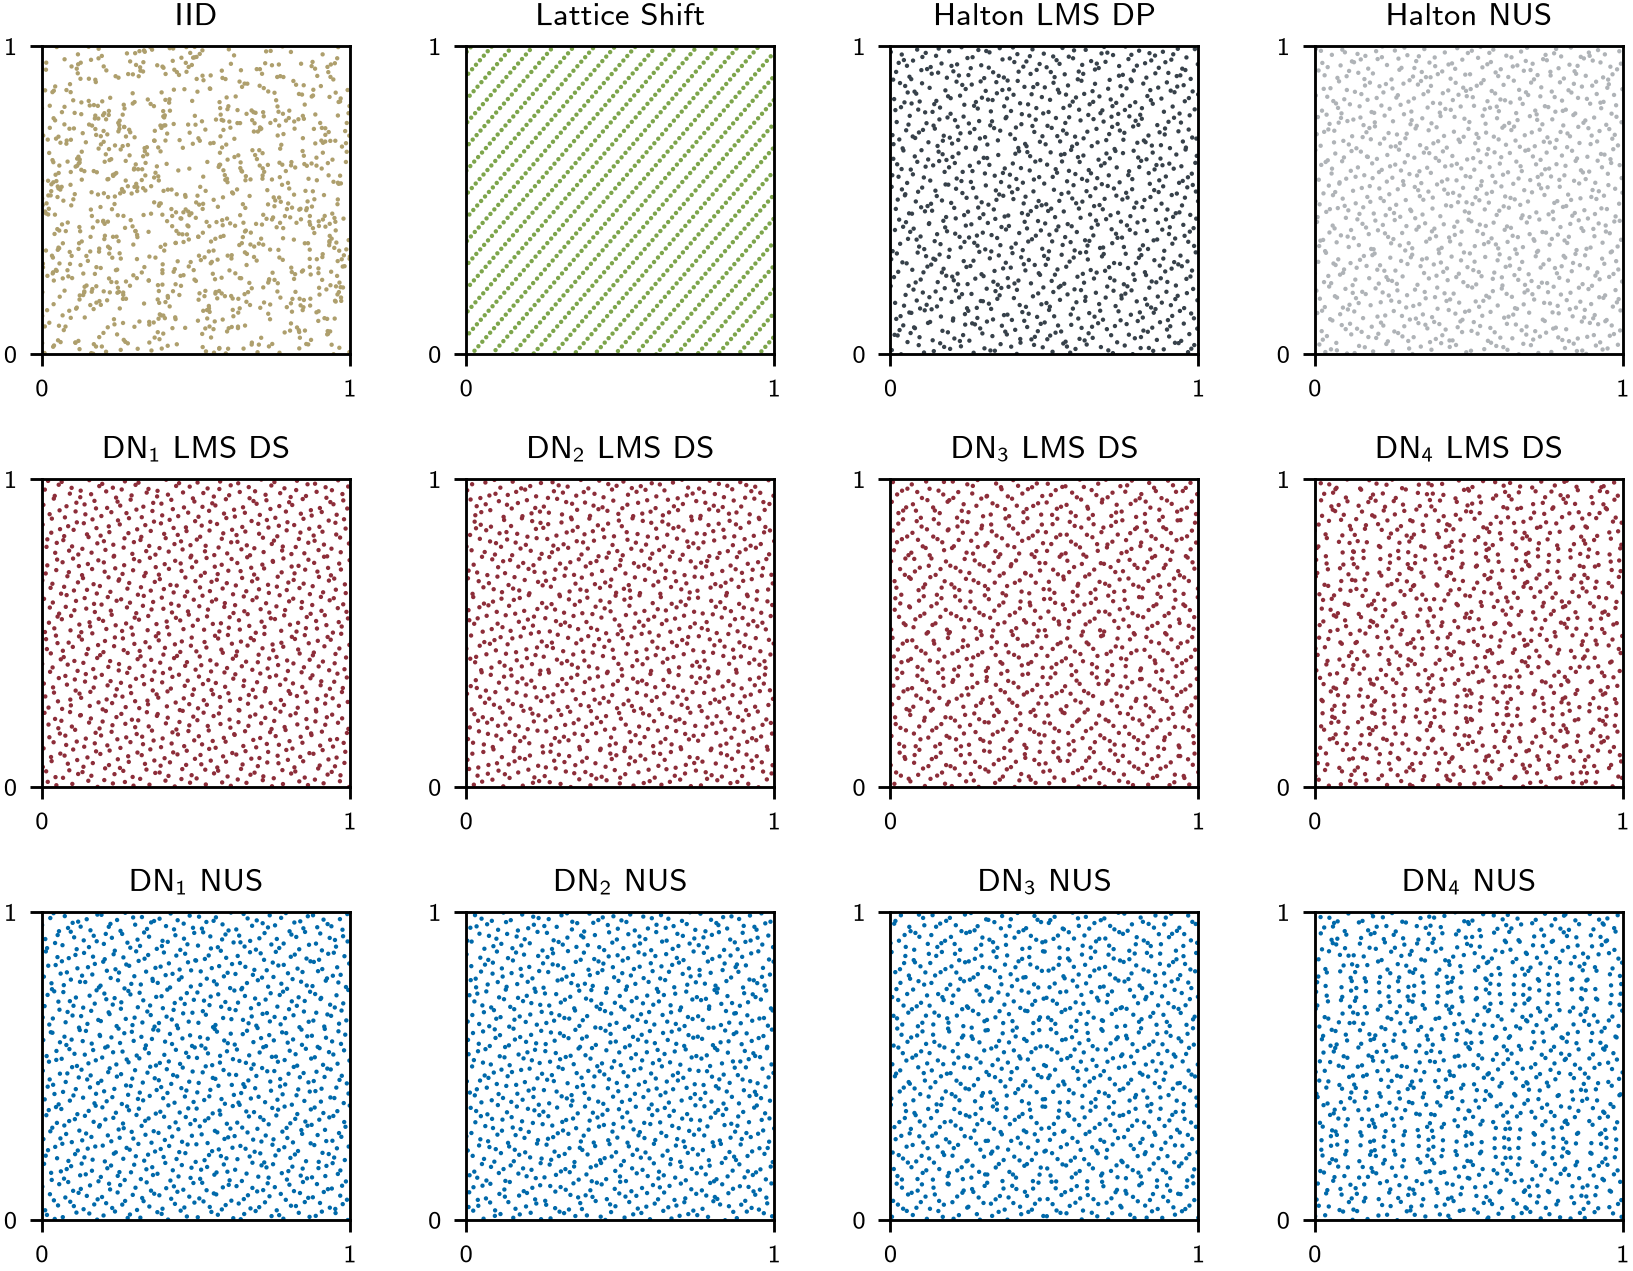

In [17]:
nrows,ncols = 3,4
assert len(pointsets)==(nrows*ncols)
fig,ax = pyplot.subplots(nrows=nrows,ncols=ncols,figsize=(MW2,MW2/ncols*nrows),constrained_layout=False,tight_layout=False)#figsize=(ncols*3,nrows*3))
s = 1.5
for i,(name,(x,pltkwargs)) in enumerate(pointsets.items()):
    ri,ci = i//ncols,i%ncols
    ax[ri,ci].set_title(name)
    ax[ri,ci].scatter(x[:,0],x[:,1],s=s,marker='o',edgecolor='none',**pltkwargs)#,fillstyle='full')
    ax[ri,ci].set_xlim([0,1]); ax[ri,ci].set_xticks([0,1])
    ax[ri,ci].set_ylim([0,1]); ax[ri,ci].set_yticks([0,1])
    ax[ri,ci].set_aspect(1)
fig.savefig("outputs/pointsets.png",format="png",dpi=1024,transparent=True,bbox_inches="tight")

## Generation time

In [18]:
reps = 5
m_max = 20

In [19]:
def time_block(pointsets_fns, rds):
    data = {}
    for name,(generator,pltkwargs) in pointsets_fns.items():
        data[name] = np.nan*np.empty((len(rds),m_max+1,reps),dtype=np.float64)
        for i,(r,d) in enumerate(rds):
            print("%25s (r=%4d, d=%4d): "%(name,r,d),end="",flush=True)
            for m in range(0,m_max+1):
                print("%d, "%m,end='',flush=True)
                for t in range(reps):
                    gc.collect()
                    t0 = time.process_time()
                    x = generator(r,2**m,d)
                    data[name][i,m,t] = time.process_time()-t0
                    del x
                if np.mean(data[name][i,m])>=.2: break
            print()
        print()
    return data 

In [20]:
pointsets_noho_fns = OrderedDict({
    r"DN${}_{1}$ LMS DS": (lambda r,n,d: qp.DigitalNetB2(d,randomize="LMS_DS",replications=r).gen_samples(n),{"color":COLORS[0],"marker":MARKERS[0]}),
    "Halton LMS DP": (lambda r,n,d: qp.Halton(d,randomize="LMS_PERM",replications=r).gen_samples(n),{"color":COLORS[1],"marker":MARKERS[1]}),
    "IID": (lambda r,n,d: qp.IIDStdUniform(d,replications=r).gen_samples(n),{"color":COLORS[2],"marker":MARKERS[2]}),
    r"DN${}_{1}$ NUS": (lambda r,n,d: qp.DigitalNetB2(d,randomize="NUS",replications=r).gen_samples(n),{"color":COLORS[3],"marker":MARKERS[3]}),
    "Halton NUS": (lambda r,n,d: qp.Halton(d,randomize="NUS",replications=r).gen_samples(n),{"color":COLORS[4],"marker":MARKERS[4]}),
    "Lattice Shift": (lambda r,n,d: qp.Lattice(d,replications=r).gen_samples(n),{"color":COLORS[5],"marker":MARKERS[5]}),
    r"SciPy DN${}_{1}$ LMS DS": (lambda r,n,d: np.stack([scipy.stats.qmc.Sobol(d=d,scramble=True,bits=63).random(n) for i in range(r)],axis=0),{"color":COLORS[6],"marker":MARKERS[6]}),
    "Halton DP": (lambda r,n,d: qp.Halton(d,randomize="DP",replications=r).gen_samples(n),{"color":COLORS[7],"marker":MARKERS[7]}),
    r"PyTorch DN${}_{1}$ LMS DS": (lambda r,n,d: np.stack([torch.quasirandom.SobolEngine(d,scramble=True).draw(n) for i in range(r)],axis=0),{"color":COLORS[8],"marker":MARKERS[8]}),
    "SciPy Halton DP": (lambda r,n,d: np.stack([scipy.stats.qmc.Halton(d=d,scramble=True).random(n) for i in range(r)],axis=0),{"color":COLORS[9],"marker":MARKERS[9]}),
})
rds_noho = np.array([
    [1,1],
    [1,100],
    [100,1],
    [10,10],
])
t_noho = time_block(pointsets_noho_fns,rds_noho) 

        DN${}_{1}$ LMS DS (r=   1, d=   1): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 
        DN${}_{1}$ LMS DS (r=   1, d= 100): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 
        DN${}_{1}$ LMS DS (r= 100, d=   1): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 
        DN${}_{1}$ LMS DS (r=  10, d=  10): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 

            Halton LMS DP (r=   1, d=   1): 0, 

/Users/alegresor/Desktop/qmcpy/qmcpy/discrete_distribution/digital_net_any_bases/digital_net_any_bases.py:398: UserWarning: It is more efficient to use DigitalNetB2 instead of DigitalNetAnyBases when all bases are 2
  warnings.warn("It is more efficient to use DigitalNetB2 instead of DigitalNetAnyBases when all bases are 2")


1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 
            Halton LMS DP (r=   1, d= 100): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 
            Halton LMS DP (r= 100, d=   1): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 
            Halton LMS DP (r=  10, d=  10): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 

                      IID (r=   1, d=   1): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 
                      IID (r=   1, d= 100): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 
                      IID (r= 100, d=   1): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 
                      IID (r=  10, d=  10): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 

           DN${}_{1}$ NUS (r=   1, d=   1): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 
           DN${}_{1}$ NUS (r=   1, d= 100): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 
       

In [21]:
pointsets_dnb2_lms_ds_nus_ho_fns = OrderedDict({
    r"DN${}_{1}$ LMS DS": (lambda r,n,d: qp.DigitalNetB2(d,randomize="LMS_DS",replications=r,alpha=1).gen_samples(n),{"color":COLORS[0],"marker":MARKERS[0]}),
    r"DN${}_{1}$ NUS": (lambda r,n,d: qp.DigitalNetB2(d,randomize="NUS",replications=r,alpha=1).gen_samples(n),{"color":COLORS[3],"marker":MARKERS[3]}),
    r"DN${}_{2}$ LMS DS": (lambda r,n,d: qp.DigitalNetB2(d,randomize="LMS_DS",replications=r,alpha=2).gen_samples(n),{"color":COLORS[0],"marker":MARKERS[1]}),
    r"DN${}_{2}$ NUS": (lambda r,n,d: qp.DigitalNetB2(d,randomize="NUS",replications=r,alpha=2).gen_samples(n),{"color":COLORS[3],"marker":MARKERS[4]}),
    r"DN${}_{3}$ LMS DS": (lambda r,n,d: qp.DigitalNetB2(d,randomize="LMS_DS",replications=r,alpha=3).gen_samples(n),{"color":COLORS[0],"marker":MARKERS[2]}),
    r"DN${}_{3}$ NUS": (lambda r,n,d: qp.DigitalNetB2(d,randomize="NUS",replications=r,alpha=3).gen_samples(n),{"color":COLORS[3],"marker":MARKERS[5]}),
    r"DN${}_{4}$ LMS DS": (lambda r,n,d: qp.DigitalNetB2(d,randomize="LMS_DS",replications=r,alpha=4).gen_samples(n),{"color":COLORS[0],"marker":MARKERS[7]}),
    r"DN${}_{4}$ NUS": (lambda r,n,d: qp.DigitalNetB2(d,randomize="NUS",replications=r,alpha=4).gen_samples(n),{"color":COLORS[3],"marker":MARKERS[6]}),
})
rds_dnb2_lms_ds_nus_ho = np.array([
    [1,1],
    [1,100],
    [100,1],
    [10,10],
])
t_dnb2_lms_ds_nus_ho = time_block(pointsets_dnb2_lms_ds_nus_ho_fns,rds_dnb2_lms_ds_nus_ho)

        DN${}_{1}$ LMS DS (r=   1, d=   1): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 
        DN${}_{1}$ LMS DS (r=   1, d= 100): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 
        DN${}_{1}$ LMS DS (r= 100, d=   1): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 
        DN${}_{1}$ LMS DS (r=  10, d=  10): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 

           DN${}_{1}$ NUS (r=   1, d=   1): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 
           DN${}_{1}$ NUS (r=   1, d= 100): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 
           DN${}_{1}$ NUS (r= 100, d=   1): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 
           DN${}_{1}$ NUS (r=  10, d=  10): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 

        DN${}_{2}$ LMS DS (r=   1, d=   1): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 
        DN${}_{2}$ LMS DS (r=   1, d= 100): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 1

In [22]:
rds_ft = np.array([
    [1,1],
    [10,1],
    [100,1],
    [1000,1],
])
assert (rds_ft[:,1]==1).all()
_rmax = 100
x_fft  = np.random.rand(_rmax*2**(m_max))+1j*np.random.rand(_rmax*2**(m_max))
x_fwht = np.random.rand(_rmax*2**(m_max))
ft_fns = OrderedDict({
    "FFT BR": (lambda r,n,d: qp.fftbr(x_fft[:r*n].reshape((r,n))),{"color":COLORS[0],"marker":MARKERS[0]}),
    "SciPy FFT": (lambda r,n,d: scipy.fft.fft(x_fft[:r*n].reshape((r,n))),{"color":COLORS[0],"marker":MARKERS[1]}),
    "IFFT BR": (lambda r,n,d: qp.ifftbr(x_fft[:r*n].reshape((r,n))),{"color":COLORS[1],"marker":MARKERS[2]}),
    "SciPy IFFT": (lambda r,n,d: scipy.fft.ifft(x_fft[:r*n].reshape((r,n))),{"color":COLORS[1],"marker":MARKERS[3]}),
    "FWHT": (lambda r,n,d: qp.fwht(x_fwht[:r*n].reshape((r,n))),{"color":COLORS[2],"marker":MARKERS[4]}),
    "SymPy FWHT": (lambda r,n,d: np.stack([sympy.fwht(x_fwht_i) for x_fwht_i in x_fwht[:r*n].reshape((r,n))],axis=0),{"color":COLORS[2],"marker":MARKERS[5]}),
})
t_ft = time_block(ft_fns,rds_ft)

                   FFT BR (r=   1, d=   1): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 
                   FFT BR (r=  10, d=   1): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 
                   FFT BR (r= 100, d=   1): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 
                   FFT BR (r=1000, d=   1): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 

                SciPy FFT (r=   1, d=   1): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 
                SciPy FFT (r=  10, d=   1): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 
                SciPy FFT (r= 100, d=   1): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 
                SciPy FFT (r=1000, d=   1): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 

                  IFFT BR (r=   1, d=   1): 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 

/var/folders/vp/7qrx483x7t595m2wjkkc_kvr0000gn/T/ipykernel_46872/2392962218.py:5: UserWarning: The Figure parameters 'tight_layout' and 'constrained_layout' cannot be used together. Please use 'layout' parameter
  fig = pyplot.figure(figsize=(MW2,MW2/ncols*nrows*1.2),constrained_layout=False,tight_layout=False)#,sharey=True,sharex=True)
/var/folders/vp/7qrx483x7t595m2wjkkc_kvr0000gn/T/ipykernel_46872/2392962218.py:10: RuntimeWarning: Mean of empty slice
  statfunc = lambda x: np.nanmean(x[:,1:],axis=1)


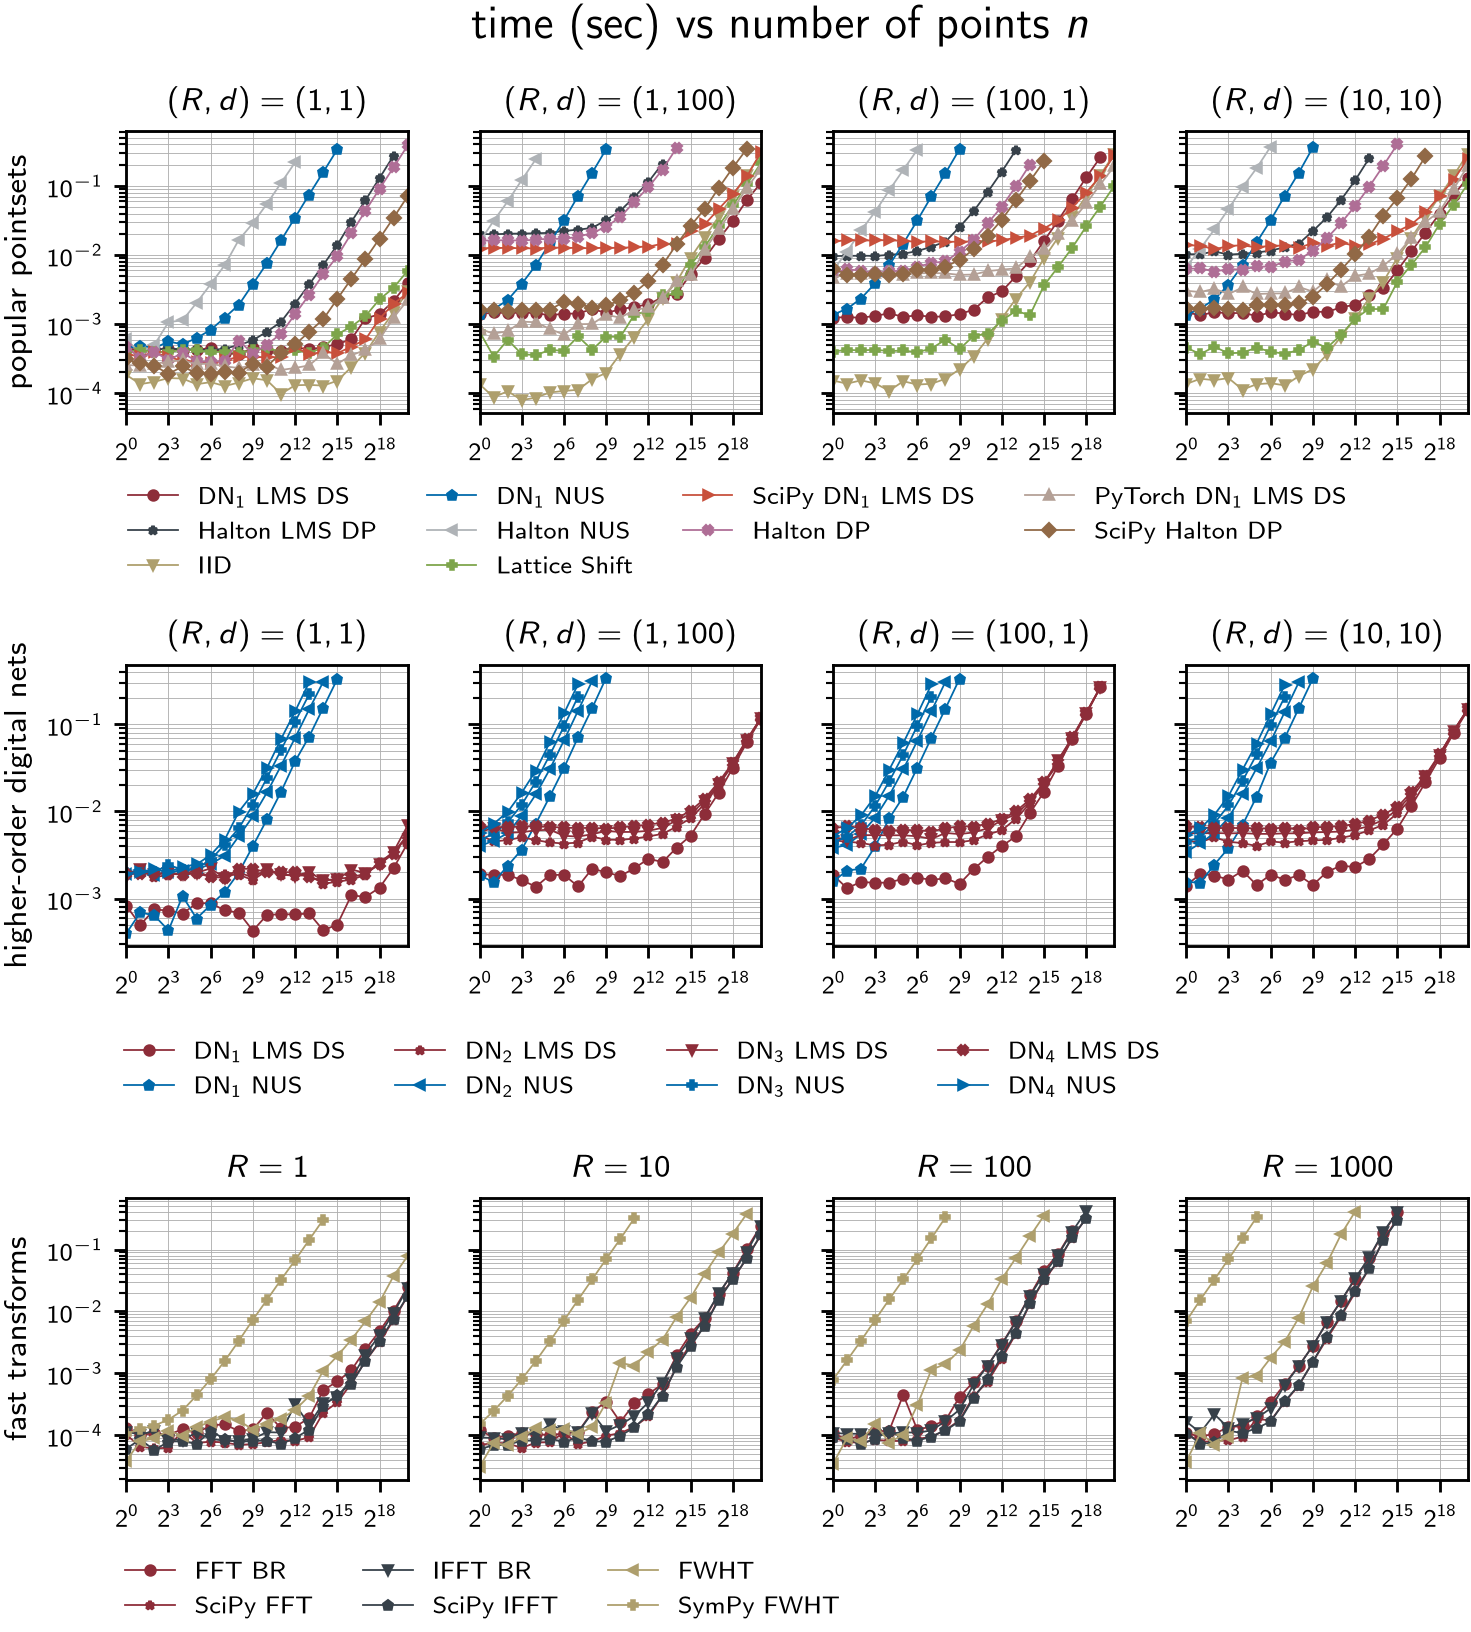

In [23]:
ncols = 4
nrows = 3
mvec = np.arange(0,m_max+1)
nvec = 2**mvec
fig = pyplot.figure(figsize=(MW2,MW2/ncols*nrows*1.2),constrained_layout=False,tight_layout=False)#,sharey=True,sharex=True)
subfigs = fig.subfigures(nrows=nrows,ncols=1)
ax = np.stack([subfigs[j].subplots(nrows=1,ncols=ncols,sharey=True,sharex=True) for j in range(nrows)],axis=0)
commonkwargs = {"markersize":2.5,"linewidth":.5}#,"markerfacecolor":'black',"markeredgecolor":'white'}
# statfunc = lambda x: np.nanquantile(x[:,1:],q=.5,axis=1)
statfunc = lambda x: np.nanmean(x[:,1:],axis=1)
for name in list(t_noho.keys()):
    for j in range(ncols):
        ax[0,j].plot(nvec,statfunc(t_noho[name][j,mvec]),label=name,**pointsets_noho_fns[name][1],**commonkwargs)
for name in list(t_dnb2_lms_ds_nus_ho.keys()):
    for j in range(ncols):
        ax[1,j].plot(nvec,statfunc(t_dnb2_lms_ds_nus_ho[name][j,mvec]),label=name,**pointsets_dnb2_lms_ds_nus_ho_fns[name][1],**commonkwargs)
for name in list(t_ft.keys()):
    for j in range(ncols):
        ax[2,j].plot(nvec,statfunc(t_ft[name][j,mvec]),label=name,**ft_fns[name][1],**commonkwargs)
subfigs[0].legend(*ax[0,0].get_legend_handles_labels(),frameon=False,bbox_to_anchor=(.925,.14),ncol=4)#,fontsize="medium")
subfigs[1].legend(*ax[1,0].get_legend_handles_labels(),frameon=False,bbox_to_anchor=(.82,.1),ncol=4)#,fontsize="medium")
subfigs[2].legend(*ax[2,0].get_legend_handles_labels(),frameon=False,bbox_to_anchor=(.64,.125),ncol=3)#,fontsize="medium")
for i in range(nrows):
    for j in range(ncols):
        ax[i,j].set_xscale('log',base=2)
        ax[i,j].set_yscale('log',base=10)
        #ax[i,j].yaxis.set_tick_params(labelleft=True)
        ax[i,j].xaxis.set_tick_params(labelbottom=True)
        ax[i,j].grid(True,which='both',linewidth=0.25)#,linestyle='--',)
        # ax[i,j].minorticks_on()
        ax[i,j].set_xlim(nvec[0],nvec[-1])
        _xmin,_xmax = ax[i,j].get_xlim()
        _ymin,_ymax = ax[i,j].get_ylim()
        ax[i,j].set_xticks(nvec[::3])
        ax[i,j].set_aspect((np.log2(_xmax)-np.log2(_xmin))/(np.log10(_ymax)-np.log10(_ymin)))
    #ax[i,0].set_ylabel('time (sec)',fontsize="xx-large")
for j in range(ncols):
    ax[0,j].set_title(r"$(R,d)=(%d,%d)$"%(rds_noho[j,0],rds_noho[j,1]))
    ax[1,j].set_title(r"$(R,d)=(%d,%d)$"%(rds_dnb2_lms_ds_nus_ho[j,0],rds_dnb2_lms_ds_nus_ho[j,1]))
    ax[2,j].set_title(r"$R=%d$"%rds_ft[j,0])
ax[0,0].set_ylabel("popular pointsets")
ax[1,0].set_ylabel("higher-order digital nets")
ax[2,0].set_ylabel("fast transforms");
fig.text(s=r"time (sec) vs number of points $n$",x=.42,y=.98,fontsize="x-large");
fig.savefig("outputs/timing.png",format="png",dpi=1024,transparent=True,bbox_inches="tight")

## Convergence

### Test Functions

In [24]:
# https://www.sfu.ca/~ssurjano/sulf.html
def sulfer_func(t):
    Tr       = t[...,0]
    fAc      = t[...,1]
    fRs      = t[...,2]
    beta_bar = t[...,3]
    Psi_e    = t[...,4]
    f_Psi_e  = t[...,5]
    Q        = t[...,6]
    Y        = t[...,7]
    L        = t[...,8]
    S0 = 1366;
    A  = 5*10**14;
    fact1 = (S0**2) * fAc * (Tr**2) * fRs**2 * beta_bar * Psi_e * f_Psi_e;
    fact2 = 3*Q*Y*L / A;
    DeltaF = -1/2 * fact1 * fact2;
    return DeltaF
sulfer_cf = qp.CustomFun(
    qp.SciPyWrapper(
        qp.IIDStdUniform(9),
        [   scipy.stats.lognorm(scale=0.76, s=np.log(1.2)),
            scipy.stats.lognorm(scale=0.39, s=np.log(1.1)),
            scipy.stats.lognorm(scale=0.85, s=np.log(1.1)),
            scipy.stats.lognorm(scale=0.3,  s=np.log(1.3)),
            scipy.stats.lognorm(scale=5.0,  s=np.log(1.4)),
            scipy.stats.lognorm(scale=1.7,  s=np.log(1.2)),
            scipy.stats.lognorm(scale=71.0, s=np.log(1.15)),
            scipy.stats.lognorm(scale=0.5,  s=np.log(1.5)),
            scipy.stats.lognorm(scale=5.5,  s=np.log(1.5)),]),
    sulfer_func)

In [25]:
# https://www.sfu.ca/~ssurjano/borehole.html 
def borehole_func(t):
    rw = t[...,0];
    r  = t[...,1];
    Tu = t[...,2];
    Hu = t[...,3];
    Tl = t[...,4];
    Hl = t[...,5];
    L  = t[...,6];
    Kw = t[...,7];
    frac1 = 2 * np.pi * Tu * (Hu-Hl);
    frac2a = 2*L*Tu / (np.log(r/rw)*rw**2*Kw);
    frac2b = Tu / Tl;
    frac2 = np.log(r/rw) * (1+frac2a+frac2b);
    y = frac1 / frac2;
    return y 
borehole_cf = qp.CustomFun(
    qp.SciPyWrapper(
        qp.IIDStdUniform(8),
        [   scipy.stats.norm(loc=0.10,scale=0.0161812),
            scipy.stats.lognorm(scale=np.exp(7.71),s=1.0056),
            scipy.stats.uniform(loc=63070,scale=115600-63070),
            scipy.stats.uniform(loc=990,scale=1110-990),
            scipy.stats.uniform(loc=63.1,scale=116-63.1),
            scipy.stats.uniform(loc=700,scale=820-700),
            scipy.stats.uniform(loc=1120,scale=1680-1120),
            scipy.stats.uniform(loc=9855,scale=12045-9855),]),
    borehole_func)

In [26]:
# https://www.sfu.ca/~ssurjano/webetal96.html
webster_cf = qp.CustomFun(
    qp.SciPyWrapper(
        qp.IIDStdUniform(2),
        [   scipy.stats.uniform(loc=1,scale=10-1),
            scipy.stats.norm(loc=2,scale=1)]),
    lambda x: x[:,0]**2+x[:,1]**3)

In [27]:
def oakley_ohagan15_func(t):
    a1 = np.array([0.0118, 0.0456, 0.2297, 0.0393, 0.1177, 0.3865, 0.3897, 0.6061, 0.6159, 0.4005, 1.0741, 1.1474, 0.7880, 1.1242, 1.1982])
    a2 = np.array([0.4341, 0.0887, 0.0512, 0.3233, 0.1489, 1.0360, 0.9892, 0.9672, 0.8977, 0.8083, 1.8426, 2.4712, 2.3946, 2.0045, 2.2621])
    a3 = np.array([0.1044, 0.2057, 0.0774, 0.2730, 0.1253, 0.7526, 0.8570, 1.0331, 0.8388, 0.7970, 2.2145, 2.0382, 2.4004, 2.0541, 1.9845])
    M = np.array([
        [-0.022482886,  -0.18501666,  0.13418263,   0.36867264,   0.17172785,   0.13651143,  -0.44034404, -0.081422854,   0.71321025,  -0.44361072,   0.50383394, -0.024101458, -0.045939684,   0.21666181,  0.055887417],
        [   0.25659630,  0.053792287,  0.25800381,   0.23795905,  -0.59125756, -0.081627077,  -0.28749073,   0.41581639,   0.49752241,  0.083893165,  -0.11056683,  0.033222351,  -0.13979497, -0.031020556,  -0.22318721],
        [ -0.055999811,   0.19542252, 0.095529005,  -0.28626530,  -0.14441303,   0.22369356,   0.14527412,   0.28998481,   0.23105010,  -0.31929879,  -0.29039128,  -0.20956898,   0.43139047,  0.024429152,  0.044904409],
        [   0.66448103,   0.43069872,  0.29924645,  -0.16202441,  -0.31479544,  -0.39026802,   0.17679822,  0.057952663,   0.17230342,   0.13466011,  -0.35275240,   0.25146896, -0.018810529,   0.36482392,  -0.32504618],
        [  -0.12127800,   0.12463327,  0.10656519,  0.046562296,  -0.21678617,   0.19492172, -0.065521126,  0.024404669, -0.096828860,   0.19366196,   0.33354757,   0.31295994, -0.083615456,  -0.25342082,   0.37325717],
        [  -0.28376230,  -0.32820154, -0.10496068,  -0.22073452,  -0.13708154,  -0.14426375,  -0.11503319,   0.22424151, -0.030395022,  -0.51505615,  0.017254978,  0.038957118,   0.36069184,   0.30902452,  0.050030193],
        [ -0.077875893, 0.0037456560,  0.88685604,  -0.26590028, -0.079325357, -0.042734919,  -0.18653782,  -0.35604718,  -0.17497421,  0.088699956,   0.40025886, -0.055979693,   0.13724479,   0.21485613, -0.011265799],
        [ -0.092294730,   0.59209563, 0.031338285, -0.033080861,  -0.24308858, -0.099798547,  0.034460195,  0.095119813,  -0.33801620, 0.0063860024,  -0.61207299,  0.081325416,   0.88683114,   0.14254905,   0.14776204],
        [  -0.13189434,   0.52878496,  0.12652391,  0.045113625,   0.58373514,   0.37291503,   0.11395325,  -0.29479222,  -0.57014085,   0.46291592, -0.094050179,   0.13959097,  -0.38607402,  -0.44897060,  -0.14602419],
        [  0.058107658,  -0.32289338, 0.093139162,  0.072427234,  -0.56919401,   0.52554237,   0.23656926, -0.011782016,  0.071820601,  0.078277291,  -0.13355752,   0.22722721,   0.14369455,  -0.45198935,  -0.55574794],
        [   0.66145875,   0.34633299,  0.14098019,   0.51882591,  -0.28019898,  -0.16032260, -0.068413337,  -0.20428242,  0.069672173,   0.23112577, -0.044368579,  -0.16455425,   0.21620977, 0.0042702105, -0.087399014],
        [   0.31599556, -0.027551859,  0.13434254,   0.13497371,  0.054005680,  -0.17374789,   0.17525393,  0.060258929,  -0.17914162,  -0.31056619,  -0.25358691,  0.025847535,  -0.43006001,  -0.62266361, -0.033996882],
        [  -0.29038151,  0.034101270, 0.034903413,  -0.12121764,  0.026030714,  -0.33546274,  -0.41424111,  0.053248380,  -0.27099455, -0.026251302,   0.41024137,   0.26636349,   0.15582891,  -0.18666254,  0.019895831],
        [  -0.24388652,  -0.44098852, 0.012618825,   0.24945112,  0.071101888,   0.24623792,   0.17484502, 0.0085286769,   0.25147070,  -0.14659862, -0.084625150,   0.36931333,  -0.29955293,   0.11044360,  -0.75690139],
        [  0.041494323,  -0.25980564,  0.46402128,  -0.36112127,  -0.94980789,  -0.16504063, 0.0030943325,  0.052792942,   0.22523648,   0.38390366,   0.45562427,  -0.18631744, 0.0082333995,   0.16670803,   0.16045688]])
    return (a1*t).sum(-1) + (a2*np.sin(t)).sum(-1) + (a3*np.cos(t)).sum(-1) + (t*np.einsum("ij,...j->...i",M,t)).sum(-1)
oakley_ohagan15_cf = qp.CustomFun(
        qp.Gaussian(qp.IIDStdUniform(15)),
        oakley_ohagan15_func)

In [28]:
def cbeam_func(t):
    R = t[...,0]
    E = t[...,1]
    X = t[...,2]
    Y = t[...,3]
    L = 100;
    D_0 = 2.2535;
    w = 4;
    t = 2;
    Sterm1 = 600*Y / (w*(t**2));
    Sterm2 = 600*X / ((w**2)*t);
    S = Sterm1 + Sterm2;
    Dfact1 = 4*(L**3) / (E*w*t);
    Dfact2 = np.sqrt((Y/(t**2))**2 + (X/(w**2))**2);
    D = Dfact1 * Dfact2
    return D 
cbeam_cf = qp.CustomFun(
    qp.Gaussian(qp.IIDStdUniform(4),mean=[40000,2.9e7,500,1000],covariance=[2000**2,1.45e6**2,100**2,100**2]),
    cbeam_func)

In [29]:
def G_func(t):
    d = t.shape[-1]
    a = (np.arange(1,d+1)-2)/2
    return ((np.abs(4*t-2)+a)/(1+a)).prod(-1)
G_cf = qp.CustomFun(
    qp.Uniform(qp.IIDStdUniform(3)),
    G_func)

In [30]:
simple_func_1d = qp.CustomFun(qp.Uniform(qp.IIDStdUniform(1)),lambda x: x[...,0]*np.exp(x[...,0])-1.)

In [31]:
simple_func_2d = qp.CustomFun(qp.Uniform(qp.IIDStdUniform(2)),lambda x: x[...,1]*np.exp(x[...,0]*x[...,1])/(np.exp(1)-2)-1)

In [32]:
oakley_ohagan_2d = qp.CustomFun(
        qp.Uniform(qp.IIDStdUniform(2),lower_bound=-0.01,upper_bound=0.01),
        lambda x: 5+x[...,0]+x[...,1]+2*np.cos(x[...,0])+2*np.sin(x[...,1]))

In [33]:
genz_oscillatory3_3d = qp.Genz(qp.IIDStdUniform(3),kind_func='oscillatory',kind_coeff=3)
genz_cornerpeak2_3d = qp.Genz(qp.IIDStdUniform(3),kind_func='corner-peak',kind_coeff=2)

In [34]:
ishigami = qp.Ishigami(qp.IIDStdUniform(3))

### Simulation

In [35]:
def convergence_block(integrands, pointsets_fns, r, m_max):
    times = {} 
    muhathats = {} 
    rmses = {}
    for name,integrand in integrands.items():
        times[name] = {} 
        muhathats[name] = {} 
        rmses[name] = {} 
        for pname,(generator,bake,pltkwargs) in pointsets_fns.items():
            times[name][pname] = np.nan*np.empty(m_max+1,dtype=np.float64)
            muhathats[name][pname] = np.nan*np.empty(m_max+1,dtype=np.float64)
            rmses[name][pname] = np.nan*np.empty(m_max+1,dtype=np.float64)
            print("%35s %-35s: "%(name,pname),end="",flush=True)
            for m in range(0,m_max+1):
                print("%d, "%m,end='',flush=True)
                t0 = timeit.default_timer()
                x = generator(r,2**m,integrand.d)
                times[name][pname][m] = timeit.default_timer()-t0
                if bake:
                    x = 1-2*np.abs(x-1/2)
                y = integrand.f(x)
                muhats = y.mean(1)
                muhathat = y.mean()
                muhathats[name][pname][m] = muhathat
                rmses[name][pname][m] = np.std(muhats,ddof=1)
            print()
        print()
    return times,muhathats,rmses

In [36]:
funcs = OrderedDict({
    r"$f(x) = x e^x - 1$": simple_func_1d,
    r"$f(x_1,x_2) = x_2 e^{x_1 x_2}/(e-2)-1$": simple_func_2d,
    r"Oakley-O'Hagan, $d=2$": oakley_ohagan_2d,
    r"G-Function, $d=%d$"%G_cf.d: G_cf,
    r"Genz Oscillatory, $d=3$": genz_oscillatory3_3d,
    r"Genz Corner-peak, $d=3$": genz_cornerpeak2_3d,
    #"Ishigami": ishigami, 
    # "Sulfer": sulfer_cf,
    #"Borehole": borehole_cf,
    # "Webster": webster_cf,
    #r"Oakley-O'Hagan with $d=15$": oakley_ohagan15_cf,
    # "Cantilever Beam": cbeam_cf,
    # r"Box Integral, $d=?$": qp.BoxIntegral(qp.IIDStdUniform(4),s=-5),
})
seed = 7
pointsets = OrderedDict({
    "IID": (lambda r,n,d: qp.IIDStdUniform(d,replications=r,seed=seed).gen_samples(n),False,{"color":COLORS[2],"marker":MARKERS[2]}),
    "Lattice Shift": (lambda r,n,d: qp.Lattice(d,replications=r,seed=seed).gen_samples(n),True,{"color":COLORS[5],"marker":MARKERS[5]}),
    r"DN${}_{1}$ LMS DS": (lambda r,n,d: qp.DigitalNetB2(d,randomize="LMS_DS",replications=r,seed=seed).gen_samples(n),False,{"color":COLORS[0],"marker":MARKERS[0]}),
    r"DN${}_{2}$ LMS DS": (lambda r,n,d: qp.DigitalNetB2(d,randomize="LMS_DS",replications=r,seed=seed,alpha=2).gen_samples(n),False,{"color":COLORS[0],"marker":MARKERS[1]}),
    r"DN${}_{3}$ LMS DS": (lambda r,n,d: qp.DigitalNetB2(d,randomize="LMS_DS",replications=r,seed=seed,alpha=3).gen_samples(n),False,{"color":COLORS[0],"marker":MARKERS[2]}),
})
m_max = 17
r = 500
times,muhathats,rmses = convergence_block(funcs,pointsets,r=r,m_max=m_max)

                 $f(x) = x e^x - 1$ IID                                : 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 
                 $f(x) = x e^x - 1$ Lattice Shift                      : 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 
                 $f(x) = x e^x - 1$ DN${}_{1}$ LMS DS                  : 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 
                 $f(x) = x e^x - 1$ DN${}_{2}$ LMS DS                  : 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 
                 $f(x) = x e^x - 1$ DN${}_{3}$ LMS DS                  : 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 

$f(x_1,x_2) = x_2 e^{x_1 x_2}/(e-2)-1$ IID                                : 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 
$f(x_1,x_2) = x_2 e^{x_1 x_2}/(e-2)-1$ Lattice Shift                      : 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 
$f(x_1,x_2) = x_2 e^{x_1 x_2}/(e-2)-1$ DN

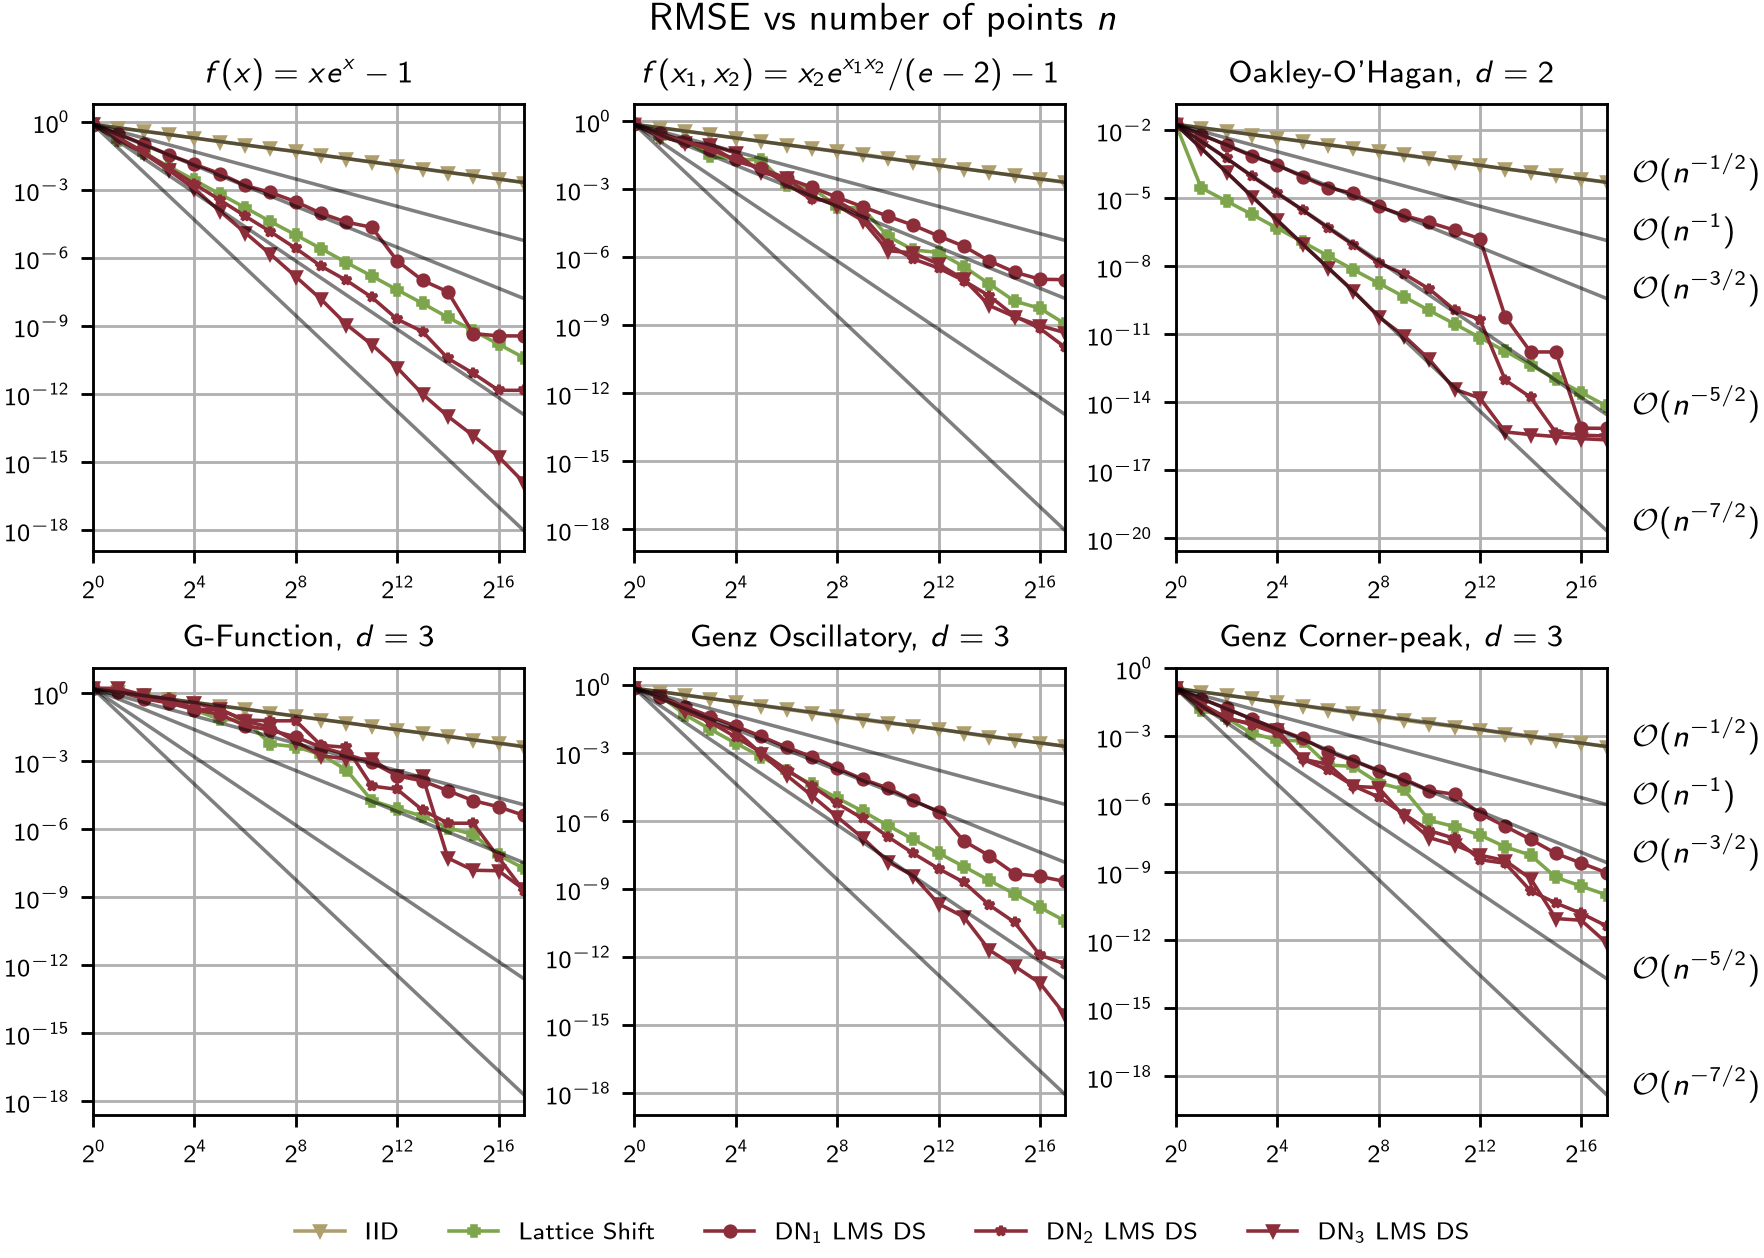

In [37]:
nrows = 2
ncols = 3 
fig,ax = pyplot.subplots(nrows=nrows,ncols=ncols,figsize=(MW2,MW2/ncols*nrows),sharey=False,sharex=True)
ax = np.atleast_1d(ax)
mvec = np.arange(0,m_max+1)
nvec = 2**mvec
commonkwargs = {"markersize":3,"linewidth":1}#,"markerfacecolor":'black',"markeredgecolor":'white'}
for i,name in enumerate(funcs.keys()):
    i1,i2 = i//ncols,i%ncols
    avgi = 0
    # avgi = rmse_noho[:,mvec[0]].mean()
    for j,(pname,(generator,bake,pltkwargs)) in enumerate(pointsets.items()):
        ax[i1,i2].plot(nvec,rmses[name][pname][mvec],label=pname,**pltkwargs,**commonkwargs)
        avgi += rmses[name][pname][mvec[0]]
    avgi /= len(pointsets)
    for p,sp in zip([-1/2,-1.,-3/2,-5/2,-7/2],["-1/2","-1","-3/2","-5/2","-7/2"]):
        n0 = 2**mvec[0]
        kappa = avgi/(n0**p)
        nf = 2**mvec[-1]
        lf = kappa*nf**p
        ax[i1,i2].plot([nvec[0],nf],[kappa*n0**p,lf],marker="none",color="black",alpha=.5,**commonkwargs)
        if i2==2:
            ax[i1,i2].text(2*nf,lf,r"$\mathcal{O}(n^{%s})$"%sp)
    ax[i1,i2].set_yscale('log',base=10)
    ax[i1,i2].set_title(name)
    ax[i1,i2].grid(True) 
    ax[i1,i2].set_xlim(nvec[0],nvec[-1])
    ax[i1,i2].set_xscale('log',base=2)
    ax[i1,i2].xaxis.set_tick_params(labelleft=True)
fig.legend(*ax[0,0].get_legend_handles_labels(),frameon=False,loc="lower center",bbox_to_anchor=(.5,-.075),ncol=5)
fig.suptitle("RMSE vs number of points $n$",fontsize="large");
fig.savefig("outputs/convergence.png",format="png",dpi=1024,transparent=True,bbox_inches="tight")